# TF-IDF + Logistic Regression Baseline Comparison

## 1. Introduction

We implement a TF-IDF + Logistic Regression model to compare against our original CNN baseline. The goal is to determine whether a traditional machine learning model can identify useful patterns in the text and achieve a higher macro F1-score than our CNN. Our original CNN achieved a test accuracy of 60.96% and a macro F1-score of 0.1692.

In [1]:
# Import libraries for data processing and model evaluation

import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

print("Libraries imported")

Libraries imported


In [2]:
# Load the cleaned dataset
df = pd.read_csv("data/clean_data.csv")

# Display dataset information
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

display(df.head())

Dataset shape: (14133, 6)

Columns: ['Unnamed: 0', 'Module Scheme Name', 'Nature', 'Description', 'Character Count', 'Type']


,Unnamed: 0,Module Scheme Name,Nature,Description,Character Count,Type
0,3,Payment,Payment/TER Charges related Query,open att file,13,Enquiry
1,4,Deficiency,Deficiency related Query,Working Email,13,Grievance
2,5,Payment,Payment Updation Issue,Payment issue,13,Grievance
3,6,Payment,Payment Updation Issue,Payment issue,13,Required Support
4,7,DSC Utility,DSC Connection Issue,PLZ DO NEEDFUL,14,Required Support


## 2. Data Preprocessing

We remove duplicate text-label pairs and descriptions associated with conflicting labels and we encode the seven categories as numerical labels to ensure a consistent dataset for comparing TF-IDF + Logistic Regression with our CNN.

In [3]:
from sklearn.preprocessing import LabelEncoder

# Remove duplicate text-label pairs
df = df.drop_duplicates(subset=["Description", "Type"]).copy()

# Remove descriptions that occur with conflicting labels
df = df.drop_duplicates(subset=["Description"], keep=False).copy()

# Reset the index
df = df.reset_index(drop=True)

# Prepare text and labels
X = df["Description"].fillna("").astype(str)
y = df["Type"]

# Encode the seven categories
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Display results
print("Dataset after duplicate removal:", df.shape)
print("\nNumber of classes:", len(label_encoder.classes_))
print("\nClass distribution:")
print(df["Type"].value_counts())

Dataset after duplicate removal: (10519, 6)

Number of classes: 7

Class distribution:
Type
Grievance             6482
Required Support      2192
Enquiry               1186
Complaint              547
Suggestion              82
Willing to Support      20
Appreciation            10
Name: count, dtype: int64


## 3. Train, Validation, and Test Split

The test set contains 15% of the observations. The remaining data is divided into training and validation sets, with 15% of the remaining observations used for validation. Stratification preserves the class distribution across the three sets.

In [4]:
from sklearn.model_selection import train_test_split

# First split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.15,
    random_state=42,
    stratify=y_encoded
)

# Second split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15,
    random_state=42,
    stratify=y_train_val
)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))
print("Total observations:", len(X_train) + len(X_val) + len(X_test))

Training observations: 7599
Validation observations: 1342
Testing observations: 1578
Total observations: 10519


## 4. TF-IDF Feature Extraction

TF-IDF will converts text into numerical features based on the importance of words across documents. We fit the TF-IDF vectorizer on the training data to prevent data leakage. We then use it to transform the validation and test sets.

In [5]:
# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    lowercase=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (7599, 10000)
Validation TF-IDF shape: (1342, 10000)
Test TF-IDF shape: (1578, 10000)


## 5. Logistic Regression Model Training

We train a Logistic Regression classifier using the TF-IDF features extracted from the training data. It serves as a comparison to our CNN baseline. We evaluate its performance using validation accuracy and macro F1-score, with macro F1 as our primary metric because the dataset is highly imbalanced.

In [6]:
# Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict on validation data
y_val_pred = lr_model.predict(X_val_tfidf)

# Calculate validation metrics
val_accuracy = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro",
    zero_division=0
)

print("TF-IDF + Logistic Regression Validation Results")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro F1: {val_macro_f1:.4f}")

TF-IDF + Logistic Regression Validation Results
Validation Accuracy: 0.6118
Validation Macro F1: 0.1626



## 6. Test Set Evaluation

We evaluate the TF-IDF + Logistic Regression model on the held-out test set using accuracy, precision, recall, and macro F1-score. We generate a classification report to examine performance across all seven categories


In [7]:

from sklearn.metrics import precision_score, recall_score

# Predict on the test set
y_test_pred = lr_model.predict(X_test_tfidf)

# Calculate test metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(
    y_test, y_test_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_test, y_test_pred, average="macro", zero_division=0
)
test_macro_f1 = f1_score(
    y_test, y_test_pred, average="macro", zero_division=0
)

print("TF-IDF + Logistic Regression Test Results")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall: {test_recall:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))


TF-IDF + Logistic Regression Test Results
Test Accuracy: 0.6299
Macro Precision: 0.2332
Macro Recall: 0.1808
Macro F1: 0.1770

Classification Report:
                    precision    recall  f1-score   support

      Appreciation       0.00      0.00      0.00         2
         Complaint       0.00      0.00      0.00        82
           Enquiry       0.65      0.24      0.35       178
         Grievance       0.64      0.95      0.77       972
  Required Support       0.34      0.08      0.12       329
        Suggestion       0.00      0.00      0.00        12
Willing to Support       0.00      0.00      0.00         3

          accuracy                           0.63      1578
         macro avg       0.23      0.18      0.18      1578
      weighted avg       0.54      0.63      0.54      1578




## 7. Confusion Matrix

The confusion matrix shows how the TF-IDF + Logistic Regression model classifies observations across the seven categories. We use it to identify which categories are frequently confused and whether the model favors the majority class, Grievance.


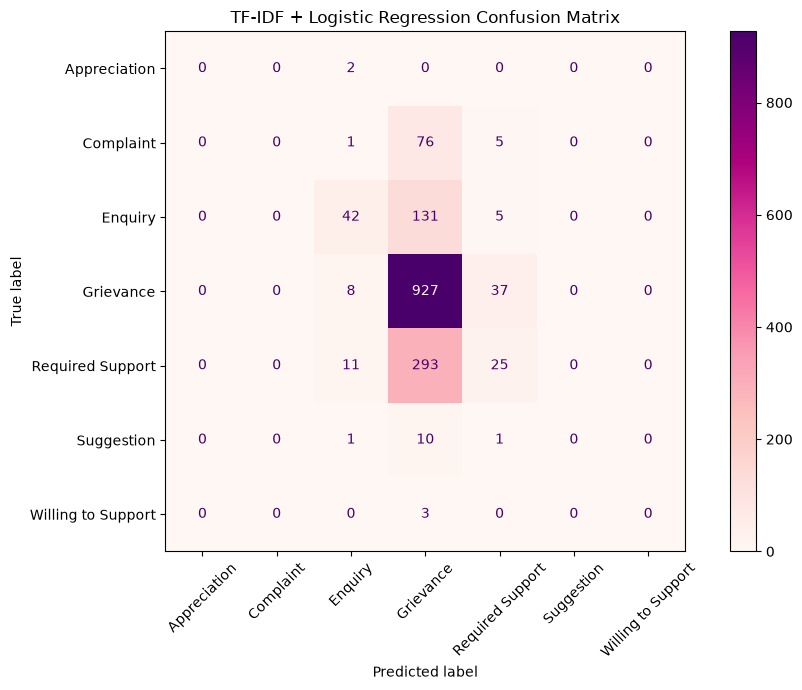

In [8]:

# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(10, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(
    ax=ax,
    cmap="RdPu",
    xticks_rotation=45,
    colorbar=True,
    values_format="d"
)

plt.title("TF-IDF + Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()



## 8. Comparison with the Original CNN Baseline

We compare TF-IDF + Logistic Regression against the original CNN baseline from Check-in 2 using the same seven classes and data splitting procedure. Macro F1 is our primary evaluation metric because it gives equal importance to each class, regardless of its size. The goal is to know if a traditional machine learning model can outperform our neural network baseline.


In [9]:

# Compare the original CNN and TF-IDF models

comparison = pd.DataFrame({
    "Model": [
        "Original CNN",
        "TF-IDF + Logistic Regression"
    ],
    "Test Accuracy": [
        0.6096,
        test_accuracy
    ],
    "Macro Precision": [
        0.2139,
        test_precision
    ],
    "Macro Recall": [
        0.1730,
        test_recall
    ],
    "Macro F1": [
        0.1692,
        test_macro_f1
    ]
})

display(comparison.round(4))

# Calculate the difference in macro F1
f1_difference = test_macro_f1 - 0.1692

print(f"Difference in Macro F1: {f1_difference:+.4f}")


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,Original CNN,0.6096,0.2139,0.1730,0.1692
1,TF-IDF + Logistic Regression,0.6299,0.2332,0.1808,0.1770


Difference in Macro F1: +0.0078



## 9. Conclusion

The TF-IDF + Logistic Regression model achieved a test accuracy of **62.99%** and a macro F1-score of **0.1770**, slightly outperforming the original CNN baseline, which achieved 60.96% accuracy and a macro F1-score of 0.1692.

Our CNN has room for improvement, as a simpler traditional machine learning model was able to achieve better results on the same classification task.

However, both models struggled with class imbalance. The TF-IDF model performed best on Grievance but failed to correctly identify four of the seven categories. The confusion matrix showed that many Enquiry and Required Support observations were incorrectly classified as Grievance.

Although TF-IDF performed slightly better overall, the improvement in macro F1 was small. Class imbalance remains a major challenge, and further improvements are needed.
